In [1]:
base ="klue/bert-base"
# base = 'BM-K/KoSimCSE-bert'

In [2]:
from utils.preprocess import *
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(base)
temp = load_data_and_tokenize(tok, "./Text Classification Dataset/train.csv")


In [3]:
ds_train, ds_test = balanced_train_test_split(temp,ratio=0.3)

In [4]:
ds_test, ds_validation = balanced_train_test_split(ds_test,ratio=0.5)

In [5]:
import torch.nn as nn
from utils.models import *

device = "cuda"
model = BertConv1dBinaryClassifier_Default(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)
optimizer = get_optimizer(model)

from transformers import DataCollatorWithPadding

num_epochs = 5
collator = DataCollatorWithPadding(tokenizer=tok)
train_model(model, ds_train, ds_test, optimizer, collator,criterion)


epoch 1 end
train_loss: 0.1441880822586221
val_loss: 0.12658844888210297
epoch 2 end
train_loss: 0.12198148780583176
val_loss: 0.11815395951271057
epoch 3 end
train_loss: 0.10729318594567668
val_loss: 0.12535971403121948
epoch 4 end
train_loss: 0.09651503045828046
val_loss: 0.11781475692987442
epoch 5 end
train_loss: 0.08418383433879557
val_loss: 0.15544091165065765


In [6]:
from torch import sigmoid
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')

loss:0.15039968490600586


In [7]:
preds, targets = get_preds(model, ds_validation, collator)

In [8]:
import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})

<Axes: xlabel='pred', ylabel='Count'>

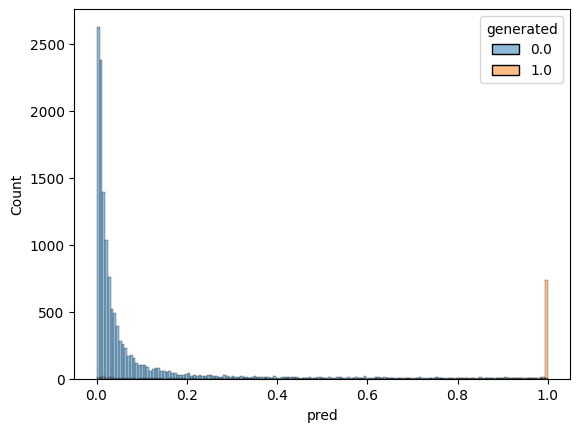

In [9]:
import seaborn as sns
sns.histplot(ret, x='pred', hue='generated')

In [ ]:
torch.save(model.state_dict(), 'BertConv1dBinaryClassifier_Default_20251119.pth')

In [5]:
import torch.nn as nn
from utils.models import *
from transformers import DataCollatorWithPadding

device = "cuda"
model = BertConv1dBinaryClassifier_MultiK(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)  # 균형이면 None
optimizer = get_optimizer(model)
collator = DataCollatorWithPadding(tokenizer=tok)

train_model(model, ds_train, ds_test, optimizer, collator, criterion, call_backs=[Save_best_model('temp'), Early_stop()])


epoch 1 end
train_loss: 0.1429032184677937
val_loss: 0.13436435163021088
saving best model...
epoch 2 end
train_loss: 0.12131515552730629
val_loss: 0.12151562422513962
saving best model...
epoch 3 end
train_loss: 0.1029057354123278
val_loss: 0.13741688430309296
epoch 4 end
train_loss: 0.08631248715059579
val_loss: 0.10643836110830307
saving best model...
epoch 5 end
train_loss: 0.06756820175242491
val_loss: 0.15288832783699036


In [7]:
state_dict = torch.load('temp',map_location='cuda')
model.load_state_dict(state_dict)

<All keys matched successfully>

In [8]:
from sklearn.metrics import accuracy_score, f1_score
def get_metric(y_pred, y_true, thres, metric='accuracy'):
    y_pred_label = [float(y >= thres) for y in y_pred]
    if metric == 'accuracy':
        return accuracy_score(y_true=y_true, y_pred=y_pred_label)
    if metric == 'f1_score':
        return f1_score(y_true=y_true, y_pred=y_pred_label)

loss:0.10258027166128159
accuracy:0.971187487137271
f1_score:0.7935103244837758


<Axes: xlabel='generated', ylabel='pred'>

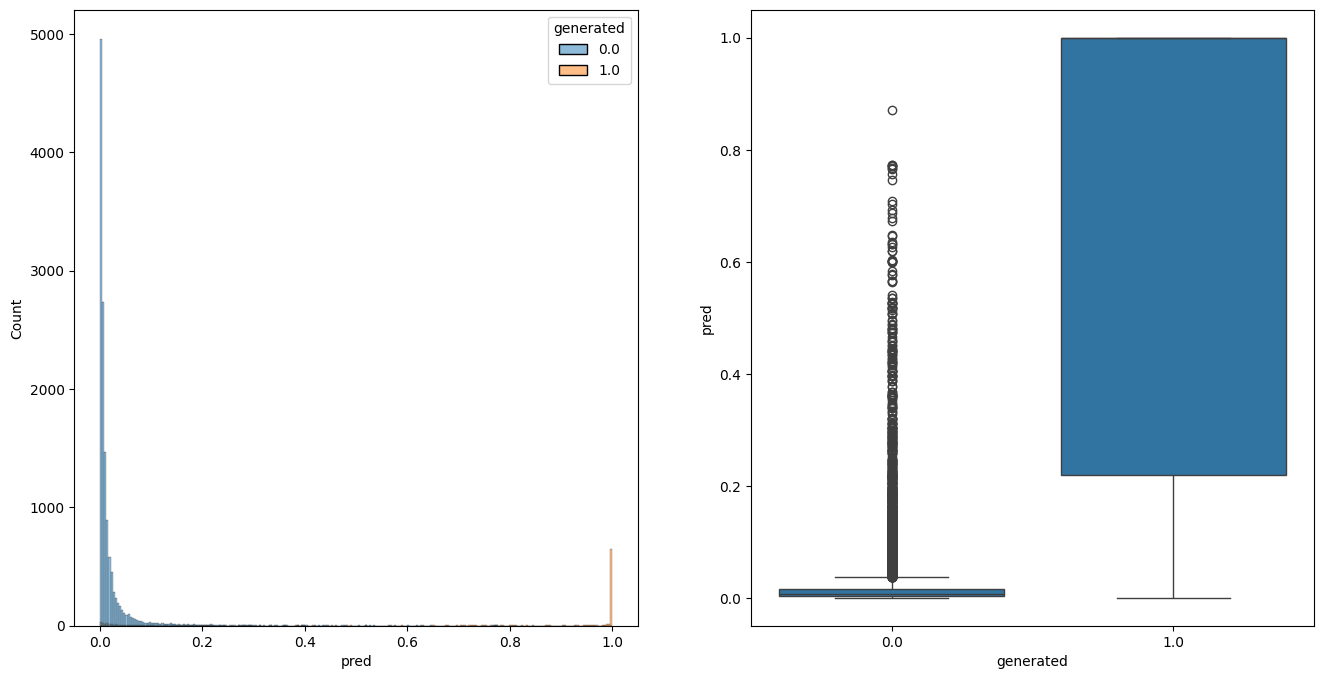

In [11]:
preds, targets = get_preds(model, ds_validation, collator)
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')
print(f'accuracy:{get_metric(preds, targets, 0.6, 'accuracy')}')
print(f'f1_score:{get_metric(preds, targets, 0.6, 'f1_score')}')

import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(16,8))
sns.histplot(ret, x='pred', hue='generated', ax=ax[0])
sns.boxplot(ret, x='generated', y='pred', ax=ax[1])

ROC AUC: 0.9431545750168199
PR AUC (AP): 0.845519250186946


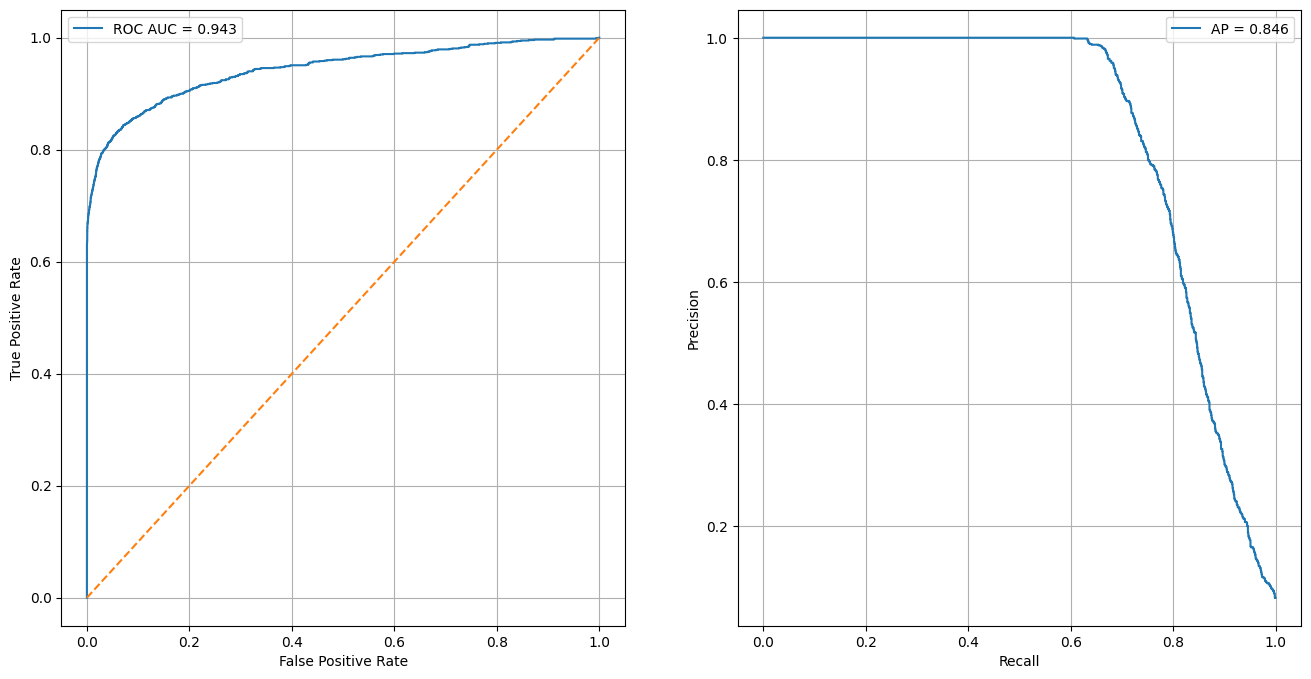

In [18]:
'''

'''
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
auc_roc = roc_auc_score(targets, preds)
ap = average_precision_score(targets, preds)

print("ROC AUC:", auc_roc)
print("PR AUC (AP):", ap)

precision, recall, thresholds_roc = precision_recall_curve(targets, preds)
fpr, tpr, thresholds_rp = roc_curve(targets, preds)

fig, ax = plt.subplots(1,2,figsize=(16,8))

ax[0].plot(fpr, tpr, label=f"ROC AUC = {auc_roc:.3f}")
ax[0].plot([0, 1], [0, 1], "--")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(recall, precision, label=f"AP = {ap:.3f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend()
ax[1].grid(True)

In [19]:
thresholds_roc

array([2.58592510e-04, 2.61132547e-04, 2.76885286e-04, ...,
       9.99999762e-01, 9.99999881e-01, 1.00000000e+00], shape=(14388,))

<Axes: xlabel='prob', ylabel='Count'>

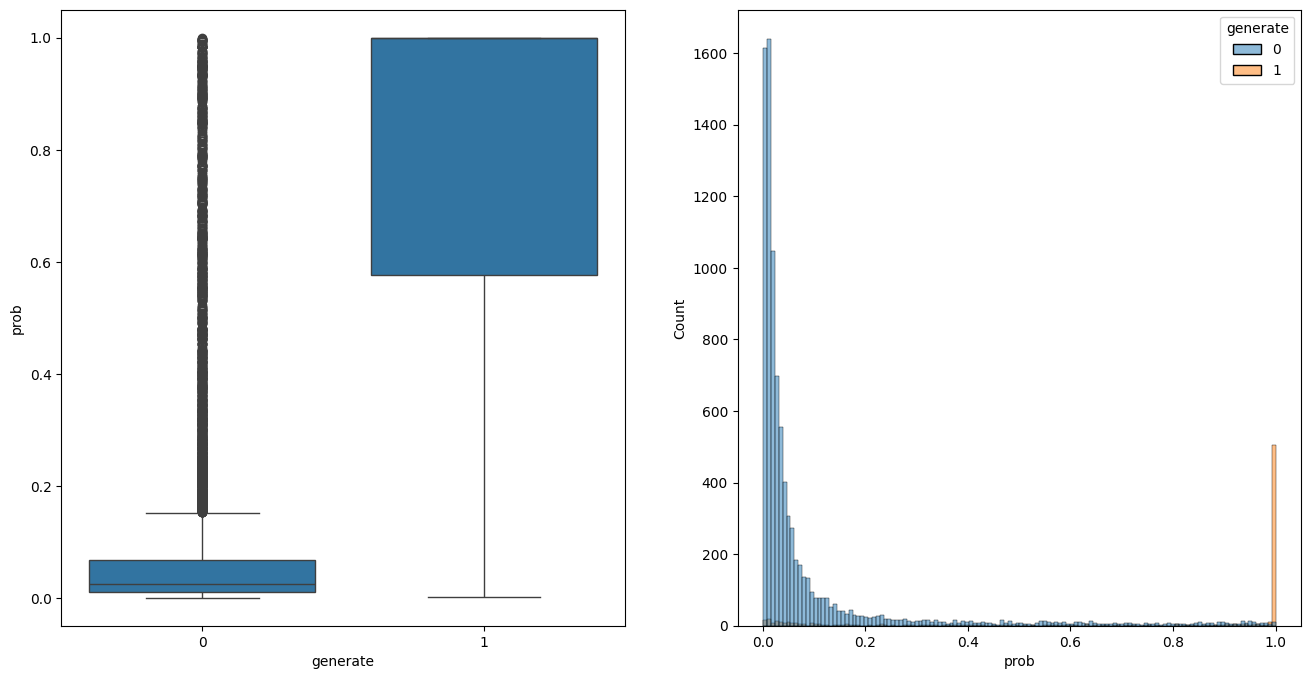

In [ ]:
#old
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(16,8))
sns.boxplot(ret, y='pred', x='generated',ax=ax[0])
sns.histplot(ret, x='pred', hue='generated', ax=ax[1])

In [ ]:
torch.save(model.state_dict(), 'BertConv1dBinaryClassifier_MultiK_20251119.pth')